## Setup

In [5]:
from pathlib import Path
DATA_DIR = Path("../data")


In [6]:
import os

# Prepend TeX bin path to the PATH environment variable
os.environ['PATH'] = '/Library/TeX/texbin:' + os.environ['PATH']

In [7]:

import matplotlib
import matplotlib.pyplot as plt

matplotlib.use("pgf")
matplotlib.rcParams.update({
    "pgf.texsystem": "pdflatex",
    'font.family': 'serif',
    'text.usetex': True,
    'pgf.rcfonts': False,
})

%matplotlib inline

<function LinearScale.__init__ at 0x115053f60>
<function LogScale.__init__ at 0x115058a40>
<function SymmetricalLogScale.__init__ at 0x1150593a0>
<function AsinhScale.__init__ at 0x115059b20>
<function LogitScale.__init__ at 0x11505a2a0>
<function FuncScale.__init__ at 0x115058400>
<function FuncScaleLog.__init__ at 0x115058d60>
<function Artist.get_agg_filter at 0x11531bd80>
<function Artist.get_alpha at 0x11531b560>
<function Artist.get_animated at 0x11531b6a0>
<function Artist.get_children at 0x11531a840>
<function Artist.get_clip_box at 0x11531b920>
<function Artist.get_clip_on at 0x11531b880>
<function Artist.get_clip_path at 0x11531b9c0>
<function Artist.get_cursor_data at 0x115360b80>
<function Artist.get_figure at 0x11531b2e0>
<function Artist.get_gid at 0x11531ade0>
<function Artist.get_in_layout at 0x11531b740>
<function Artist.get_label at 0x1153602c0>
<function Artist.get_mouseover at 0x115360cc0>
<function Artist.get_path_effects at 0x11531b240>
<function Artist.get_picker

In [1]:
def asbool(x):
    if isinstance(x, bool):
        return x
    elif isinstance(x, str):
        return x.lower() in ["true", "1", "yes"]
    elif isinstance(x, int):
        return x == 1
    else:
        return False

asbool(True), asbool("True"), asbool("1"), asbool(1), asbool("yes"), asbool(False), asbool("false"), asbool("0"), asbool(0), asbool("no")

(True, True, True, True, True, False, False, False, False, False)

# Tool calls

In [ ]:
import zipfile
import json
from tqdm import tqdm

#zip_path = "../data/traces/PatchFinder_top10_Llama-3.3-70B-Instruct_traces.jsonl.zip"

def load_traces(zip_path):
    traces = {}
    with zipfile.ZipFile(zip_path) as z:
        # Get the single file name inside the archive
        inner_name = z.namelist()[0]
        print(z.namelist())
        # Open the file for streaming
        with z.open(inner_name, "r") as f:
            for line in tqdm(f, total=5566212):
                # Decode bytes → str
                line = line.decode("utf-8").strip()
                if not line:
                    continue
                record = json.loads(line)
                span = record["resourceSpans"][0]["scopeSpans"][0]["spans"][0]
                
                call = span["name"]
                
                stats = traces.get(span["traceId"], {})
                stats[span["startTimeUnixNano"]] = call
                #stats[call] = stats.get("startTimeUnixNano", 0) + 1
                traces[span["traceId"]] = stats
    print(f"Loaded {len(traces)} traces from {zip_path}")
    return traces
            # {asdasd: {383847: call}}
            #res[span] = res.get(call, 0) + 1 
            #if "parentSpanId" in span:
            #    res[span[]]
            #res2.append(record)
            #i+=1
            #if i > 10000: break
            # process the JSON record here
            

In [10]:
import pandas as pd

def load_steps_data(filepath, traces):
    with open(filepath, 'r') as f:
        data = []
        for line in tqdm(f):
            data.append(json.loads(line))
        df = pd.DataFrame(data)
    
        results = {}
        for idx, example in tqdm(df.iterrows(), total=len(df)):
            answer = asbool(example["output"]["answer"])
            label =  asbool(example["input"]["label"])
            
            
            #correct = answer == label
            #if correct:
            #    continue
            #if label == True:
            #    continue
            
            
            #print(correct, answer, label)
            #print(example)
            traceid = example["metadata"]["trace_id"]
            #print(traceid)
            trace = traces[traceid]
            #print(trace)
            times = list(trace.keys())
            times.sort()
            
            step = -1
            skip = False
            previous = None
            for time in times:
                step_call = trace[time]
                if step_call == "CodeAgent.run":
                    skip = False
                    previous = None
                    continue
                if step_call == "OpenAIServerModel.generate":
                    previous = None
                    if not skip:
                        step += 1
                        skip = True
                    else:
                        skip = False
                    continue
                if previous == step_call:
                    continue
                else:
                    previous = step_call
                stats = results.get(step, {})
                stats[step_call] = stats.get(step_call, 0) + 1
                results[step] = stats
                skip = False
                
        return results, df

        

In [11]:
TOOL_ORDER = [
    "FinalAnswerTool",
    "CVEReportTool",
    "CWEReportTool",
    "CodeSearchTool",
    "FileSearchTool",
    "OpenFileTool",
    "ScrollFileTool",
]

COLOR_MAP = {
    "FinalAnswerTool": "#1f77b4",   # blue
    "CVEReportTool":   "#ff7f0e",   # orange
    "CodeSearchTool":  "#2ca02c",   # green
    "FileSearchTool":  "#d62728",   # red
    "OpenFileTool":    "#9467bd",   # purple
    "ScrollFileTool":  "#8c564b",   # brown
    "CWEReportTool":   "#e377c2",   # pink
}


In [ ]:


jsonl_files = [
 'PatchFinder_top10_Qwen3-235B-A22B-Instruct-2507.jsonl',
 'PatchFinder_top10_Llama-3.3-70B-Instruct.jsonl',
 'PatchFinder_top10_gemma-3-27b-it-new-clean.jsonl'
]

for file in jsonl_files:
    subset = "_".join(file.split("_")[0:2])
    model = file.split("_")[-1].replace(".jsonl", "")
    print(subset, model)
    results_path = DATA_DIR / "output" / f"{subset}_{model}.jsonl"
    trace_path = DATA_DIR / "traces" / f"{subset}_{model}_traces.jsonl.zip"

    print("Loading traces from:", trace_path)
    traces = load_traces(trace_path)
    steps, df = load_steps_data(results_path, traces)
    
    i = 0
    j = 0
    k = 0
    for trace in traces.values():
        
        if "CVEReportTool" not in trace.values() and "FinalAnswerTool" in trace.values():
            j += 1
            
        if "FinalAnswerTool" in trace.values():
            k += 1
        
        i += 1
    print(file, i, j, k)

In [33]:


jsonl_files = [
 #'random_10_Qwen3-235B-A22B-Instruct-2507.jsonl',
 #'random_10_Llama-3.3-70B-Instruct.jsonl',
 'random_10_gemma-3-27b-it-new-clean.jsonl'
]

for file in jsonl_files:
    subset = "_".join(file.split("_")[0:2])
    model = file.split("_")[-1].replace(".jsonl", "")
    print(subset, model)
    results_path = DATA_DIR / "output" / f"{subset}_{model}.jsonl"
    trace_path = DATA_DIR / "traces" / f"{subset}_{model}_traces.jsonl.zip"

    print("Loading traces from:", trace_path)
    traces = load_traces(trace_path)
    steps, df = load_steps_data(results_path, traces)
    
    
    i = 0
    j = 0
    k = 0
    
    
    for _, row in tqdm(df.iterrows(), total=len(df)):
        
        #if row["output"].get("answer") is None:
        #        continue
        #
        #if asbool(row["input"]["label"]) != row["output"]["answer"]:
        #    continue
            
        
        traceid = row["metadata"]["trace_id"]
        trace = traces[traceid]
        if "CVEReportTool" not in trace.values() and "FinalAnswerTool" in trace.values():
            j += 1
            
        if "FinalAnswerTool" in trace.values():
            k += 1
        
        i += 1
    print(file, i, j, k)

random_10 gemma-3-27b-it-new-clean
Loading traces from: ../data/traces/random_10_gemma-3-27b-it-new-clean_traces.jsonl.zip
['random_10_gemma-3-27b-it_traces.jsonl']


  3%|▎         | 153020/5566212 [01:08<40:25, 2232.18it/s]  


Loaded 12290 traces from ../data/traces/random_10_gemma-3-27b-it-new-clean_traces.jsonl.zip


12290it [00:00, 35124.01it/s]
100%|██████████| 12290/12290 [00:00<00:00, 64997.30it/s]

random_10_gemma-3-27b-it-new-clean.jsonl 12290 46 10691


In [52]:
df["metadata"].iloc[0]["output"]["answer"]

KeyError: 'output'

In [69]:
count = 0
for x in data[('PatchFinder_top10', 'Qwen3-235B-A22B-Instruct-2507')].values():
    if "FinalAnswerTool" in x:
        count += x["FinalAnswerTool"]
print(count)
count = 0
for x in data[('PatchFinder_top10', 'Llama-3.3-70B-Instruct')].values():
    if "FinalAnswerTool" in x:
        count += x["FinalAnswerTool"]
print(count)
count = 0
for x in data[('PatchFinder_top10', 'gemma-3-27b-it-new-clean')].values():
    if "FinalAnswerTool" in x:
        count += x["FinalAnswerTool"]
print(count)


1023
1009
932


In [16]:
count = 0
for x in data[('PatchFinder_top10', 'Qwen3-235B-A22B-Instruct-2507')].values():
    if "CVEReportTool" in x:
        count += x["CVEReportTool"]
print(count)
count = 0
for x in data[('PatchFinder_top10', 'Llama-3.3-70B-Instruct')].values():
    if "CVEReportTool" in x:
        count += x["CVEReportTool"]
print(count)
count = 0
for x in data[('PatchFinder_top10', 'gemma-3-27b-it-new-clean')].values():
    if "CVEReportTool" in x:
        count += x["CVEReportTool"]
print(count)


1683
2282
3127


In [34]:
count = 0
for x in data[('PatchFinder_top10', 'Qwen3-235B-A22B-Instruct-2507')][0].values():
    if "CVEReportTool" in x:
        count += x["CVEReportTool"]
print(count)
count = 0
for x in data[('PatchFinder_top10', 'Llama-3.3-70B-Instruct')][0].values():
    if "CVEReportTool" in x:
        count += x["CVEReportTool"]
print(count)
count = 0
for x in data[('PatchFinder_top10', 'gemma-3-27b-it-new-clean')][0].values():
    if "CVEReportTool" in x:
        count += x["CVEReportTool"]
print(count)


12715
11902
11081


In [ ]:
qwen: 0 / 10121
llama: 2958 / 9981
gemma: 61 / 7441



In [19]:

jsonl_files = [
 'PatchFinder_top10_Qwen3-235B-A22B-Instruct-2507.jsonl',
 'PatchFinder_top10_Llama-3.3-70B-Instruct.jsonl',
 'PatchFinder_top10_gemma-3-27b-it-new-clean.jsonl'
]

data = {}
for file in jsonl_files:

    subset = "_".join(file.split("_")[0:2])
    model = file.split("_")[-1].replace(".jsonl", "")
    print(subset, model)
    results_path = DATA_DIR / "output" / f"{subset}_{model}.jsonl"
    trace_path = DATA_DIR / "traces" / f"{subset}_{model}_traces.jsonl.zip"
    
    print("Loading traces from:", trace_path)
    traces = load_traces(trace_path)
    steps = load_steps_data(results_path, traces)
    
    data[(subset, model)] = steps

PatchFinder_top10 Qwen3-235B-A22B-Instruct-2507
Loading traces from: ../data/traces/PatchFinder_top10_Qwen3-235B-A22B-Instruct-2507_traces.jsonl.zip
['PatchFinder_top10_Qwen3-235B-A22B-Instruct-2507_traces.jsonl']


100%|██████████| 5566212/5566212 [03:41<00:00, 25161.78it/s]


Loaded 12456 traces from ../data/traces/PatchFinder_top10_Qwen3-235B-A22B-Instruct-2507_traces.jsonl.zip


12366it [00:00, 24776.55it/s]
100%|██████████| 12366/12366 [00:00<00:00, 30081.15it/s]


PatchFinder_top10 Llama-3.3-70B-Instruct
Loading traces from: ../data/traces/PatchFinder_top10_Llama-3.3-70B-Instruct_traces.jsonl.zip
['PatchFinder_top10_Llama-3.3-70B-Instruct_traces.jsonl']


  2%|▏         | 97175/5566212 [00:28<26:56, 3383.26it/s]


... (2 outputs left out)

PatchFinder_top10 gemma-3-27b-it-new-clean
Loading traces from: ../data/traces/PatchFinder_top10_gemma-3-27b-it-new-clean_traces.jsonl.zip
['PatchFinder_top10_gemma-3-27b-it_traces.jsonl']


  3%|▎         | 146086/5566212 [01:14<45:59, 1963.89it/s]  


Loaded 12222 traces from ../data/traces/PatchFinder_top10_gemma-3-27b-it-new-clean_traces.jsonl.zip


12222it [00:00, 28405.88it/s]
100%|██████████| 12222/12222 [00:00<00:00, 56533.27it/s]


In [15]:
count = 0
for x in data[('PatchFinder_top10', 'Qwen3-235B-A22B-Instruct-2507')].values():
    if "FinalAnswerTool" in x:
        count += x["FinalAnswerTool"]
print(count)
count = 0
for x in data[('PatchFinder_top10', 'Llama-3.3-70B-Instruct')].values():
    if "FinalAnswerTool" in x:
        count += x["FinalAnswerTool"]
print(count)
count = 0
for x in data[('PatchFinder_top10', 'gemma-3-27b-it-new-clean')].values():
    if "FinalAnswerTool" in x:
        count += x["FinalAnswerTool"]
print(count)


1597
2342
3099


Global max: 14279.0


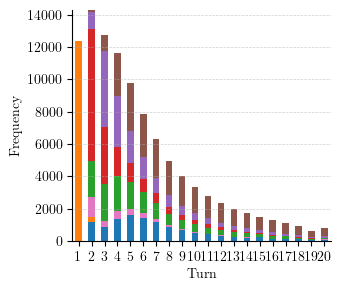

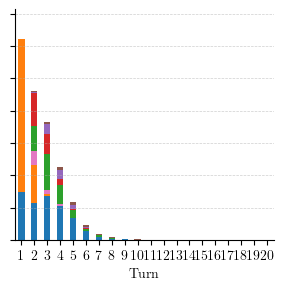

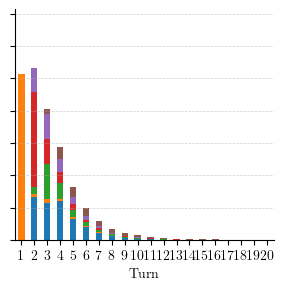

In [20]:
global_max = 0
for steps in data.values():
    df_tmp = pd.DataFrame(steps[0]).T
    global_max = max(global_max, df_tmp.sum(axis=1).max())
print("Global max:", global_max)

for idx, ((subset, model), steps) in enumerate(data.items()):
    fig, ax = plt.subplots(figsize=(4, 3.2))

    df = pd.DataFrame(steps[0]).T
    df = df.reindex(columns=TOOL_ORDER, fill_value=0)
    colors = [COLOR_MAP[c] for c in TOOL_ORDER]

    df.plot.bar(
        stacked=True,
        legend=False,
        ax=ax,
        color=colors
    )


    ax.grid(axis="y", linestyle="--", linewidth=0.5, alpha=0.6)

    # Only the first figure gets y-labels
    if idx == 0:
        ax.set_ylabel("Frequency")
    else:
        ax.set_ylabel("")
        ax.set_yticklabels([])

    # Title
    #ax.set_title(f"{subset}\n{model}", fontsize=4)

    ax.set_ylim(0, global_max)
    

    # X-axis
    ax.set_xlabel("Turn")
    ax.set_xticks(range(20))          # ticks at 0,1,...,19
    ax.set_xticklabels(range(1, 21))  # labels 1,2,...,20
    ax.set_xlabel("Turn")
    plt.xticks(rotation=0)
    
    for spine in ["top", "right"]:
        ax.spines[spine].set_visible(False)
        
    # Only the last figure gets a legend
   #if idx == len(data) - 1:
   #    handles, labels = ax.get_legend_handles_labels()
   #    sorted_pairs = sorted(zip(handles, labels), key=lambda x: TOOL_ORDER.index(x[1]))
   #    handles, labels = zip(*sorted_pairs)
   #    fig.legend(
   #        handles,
   #        labels,
   #        frameon=False,
   #        loc="upper right",
   #        bbox_to_anchor=(0.92, 0.87)
   #    )
        
        
    fig.set_size_inches(w=3.3374, h=(3))

    #fig.tight_layout(rect=[0, 0, 1, 0.92] if idx == len(data) - 1 else None)

    fig.savefig(f'../figures/tool_calls_{subset}_{model}.pdf', bbox_inches='tight')
    #fig.savefig(f'../figures/tool_calls_{subset}_{model}_nopatch.pdf', bbox_inches='tight')
    #fig.savefig(f'../figures/tool_calls_{subset}_{model}_patch.pgf', bbox_inches='tight')
    plt.show()

In [21]:
subset

'PatchFinder_top10'

## Random

In [16]:

jsonl_files = [
 'random_10_Qwen3-235B-A22B-Instruct-2507.jsonl',
 'random_10_Llama-3.3-70B-Instruct.jsonl',
 'random_10_gemma-3-27b-it-new-clean.jsonl'
]

data = {}
for file in jsonl_files:

    subset = "_".join(file.split("_")[0:2])
    model = file.split("_")[-1].replace(".jsonl", "")
    print(subset, model)
    results_path = DATA_DIR / "output" / f"{subset}_{model}.jsonl"
    trace_path = DATA_DIR / "traces" / f"{subset}_{model}_traces.jsonl.zip"
    
    print("Loading traces from:", trace_path)
    traces = load_traces(trace_path)
    steps = load_steps_data(results_path, traces)
    
    data[(subset, model)] = steps

random_10 Qwen3-235B-A22B-Instruct-2507
Loading traces from: ../data/traces/random_10_Qwen3-235B-A22B-Instruct-2507_traces.jsonl.zip
['random_10_Qwen3-235B-A22B-Instruct-2507_traces.jsonl']


 79%|███████▉  | 4390111/5566212 [02:54<00:46, 25150.16it/s]


Loaded 12446 traces from ../data/traces/random_10_Qwen3-235B-A22B-Instruct-2507_traces.jsonl.zip


12372it [00:00, 32861.34it/s]
100%|██████████| 12372/12372 [00:00<00:00, 19270.94it/s]


random_10 Llama-3.3-70B-Instruct
Loading traces from: ../data/traces/random_10_Llama-3.3-70B-Instruct_traces.jsonl.zip
['random_10_Llama-3.3-70B-Instruct_traces.jsonl']


  2%|▏         | 99577/5566212 [00:29<26:38, 3418.89it/s]


... (2 outputs left out)

random_10 gemma-3-27b-it-new-clean
Loading traces from: ../data/traces/random_10_gemma-3-27b-it-new-clean_traces.jsonl.zip
['random_10_gemma-3-27b-it_traces.jsonl']


  3%|▎         | 153020/5566212 [01:06<39:06, 2307.39it/s]  


Loaded 12290 traces from ../data/traces/random_10_gemma-3-27b-it-new-clean_traces.jsonl.zip


12290it [00:00, 34925.77it/s]
100%|██████████| 12290/12290 [00:00<00:00, 57848.64it/s]


In [ ]:


jsonl_files = [
 'random_10_Qwen3-235B-A22B-Instruct-2507.jsonl',
 'random_10_Llama-3.3-70B-Instruct.jsonl',
 'random_10_gemma-3-27b-it-new-clean.jsonl'
]

for file in jsonl_files:
    subset = "_".join(file.split("_")[0:2])
    model = file.split("_")[-1].replace(".jsonl", "")
    print(subset, model)
    

random_10 Qwen3-235B-A22B-Instruct-2507
Loading traces from: ../data/traces/random_10_Qwen3-235B-A22B-Instruct-2507_traces.jsonl.zip
['random_10_Qwen3-235B-A22B-Instruct-2507_traces.jsonl']


 79%|███████▉  | 4390111/5566212 [02:53<00:46, 25241.15it/s]


Loaded 12446 traces from ../data/traces/random_10_Qwen3-235B-A22B-Instruct-2507_traces.jsonl.zip
random_10_Qwen3-235B-A22B-Instruct-2507.jsonl 12446 0
random_10 Llama-3.3-70B-Instruct
Loading traces from: ../data/traces/random_10_Llama-3.3-70B-Instruct_traces.jsonl.zip
['random_10_Llama-3.3-70B-Instruct_traces.jsonl']


  2%|▏         | 99577/5566212 [00:31<29:09, 3124.92it/s]


Loaded 12476 traces from ../data/traces/random_10_Llama-3.3-70B-Instruct_traces.jsonl.zip
random_10_Llama-3.3-70B-Instruct.jsonl 12476 2421
random_10 gemma-3-27b-it-new-clean
Loading traces from: ../data/traces/random_10_gemma-3-27b-it-new-clean_traces.jsonl.zip
['random_10_gemma-3-27b-it_traces.jsonl']


  3%|▎         | 153020/5566212 [01:09<40:40, 2217.68it/s]  

Loaded 12290 traces from ../data/traces/random_10_gemma-3-27b-it-new-clean_traces.jsonl.zip
random_10_gemma-3-27b-it-new-clean.jsonl 12290 46


In [ ]:
    results_path = DATA_DIR / "output" / f"{subset}_{model}.jsonl"
    trace_path = DATA_DIR / "traces" / f"{subset}_{model}_traces.jsonl.zip"

    print("Loading traces from:", trace_path)
    traces = load_traces(trace_path)
    
    i = 0
    j = 0
    k = 0
    for trace in traces.values():
        
        if "CVEReportTool" not in trace.values() and "FinalAnswerTool" in trace.values():
            j += 1
        if "FinalAnswerTool" in trace.values():
            k += 1
        
        i += 1
    print(file, i, j)

Loading traces from: ../data/traces/random_10_gemma-3-27b-it-new-clean_traces.jsonl.zip
['random_10_gemma-3-27b-it_traces.jsonl']


  0%|          | 6630/5566212 [00:03<49:22, 1876.79it/s]  


KeyboardInterrupt: 

In [ ]:
load_steps_data(results_path, traces)[1]["output"][]

12290it [00:00, 31863.24it/s]
100%|██████████| 12290/12290 [00:00<00:00, 64304.86it/s]


0        {'answer': True, 'confidence': 5, 'explanation...
1        {'answer': None, 'confidence': None, 'explanat...
2        {'answer': True, 'confidence': 3, 'explanation...
3        {'answer': True, 'confidence': 4, 'explanation...
4        {'answer': True, 'confidence': 4, 'explanation...
                               ...                        
12285    {'answer': False, 'confidence': 4, 'explanatio...
12286    {'answer': False, 'confidence': 5, 'explanatio...
12287    {'answer': False, 'confidence': 5, 'explanatio...
12288    {'answer': False, 'confidence': 5, 'explanatio...
12289    {'answer': False, 'confidence': 5, 'explanatio...
Name: output, Length: 12290, dtype: object

In [ ]:
Qwen 0 / 11368
Llama 2421 / 11559
gemma 46 / 9549

In [12]:
count = 0
for x in data[('random_10', 'Qwen3-235B-A22B-Instruct-2507')].values():
    if "FinalAnswerTool" in x:
        count += x["FinalAnswerTool"]
print(count)
count = 0
for x in data[('random_10', 'Llama-3.3-70B-Instruct')].values():
    if "FinalAnswerTool" in x:
        count += x["FinalAnswerTool"]
print(count)
count = 0
for x in data[('random_10', 'gemma-3-27b-it-new-clean')].values():
    if "FinalAnswerTool" in x:
        count += x["FinalAnswerTool"]
print(count)


355
548
1026


Global max: 14304.0


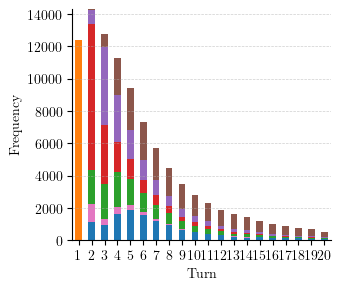

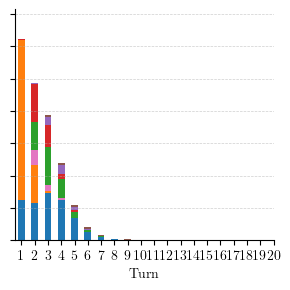

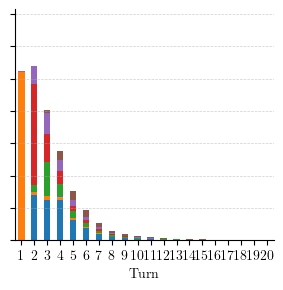

In [17]:
global_max = 0
for steps in data.values():
    df_tmp = pd.DataFrame(steps[0]).T
    global_max = max(global_max, df_tmp.sum(axis=1).max())
print("Global max:", global_max)

for idx, ((subset, model), steps) in enumerate(data.items()):
    fig, ax = plt.subplots(figsize=(4, 3.2))

    df = pd.DataFrame(steps[0]).T
    df = df.reindex(columns=TOOL_ORDER, fill_value=0)
    colors = [COLOR_MAP[c] for c in TOOL_ORDER]

    df.plot.bar(
        stacked=True,
        legend=False,
        ax=ax,
        color=colors
    )


    ax.grid(axis="y", linestyle="--", linewidth=0.5, alpha=0.6)

    # Only the first figure gets y-labels
    if idx == 0:
        ax.set_ylabel("Frequency")
    else:
        ax.set_ylabel("")
        ax.set_yticklabels([])

    # Title
    #ax.set_title(f"{subset}\n{model}", fontsize=4)

    ax.set_ylim(0, global_max)

    # X-axis
    ax.set_xlabel("Turn")
    ax.set_xticks(range(20))          # ticks at 0,1,...,19
    ax.set_xticklabels(range(1, 21))  # labels 1,2,...,20
    ax.set_xlabel("Turn")
    plt.xticks(rotation=0)
    
    for spine in ["top", "right"]:
        ax.spines[spine].set_visible(False)
        

    # Only the last figure gets a legend
   #if idx == len(data) - 1:
   #    handles, labels = ax.get_legend_handles_labels()
   #    sorted_pairs = sorted(zip(handles, labels), key=lambda x: TOOL_ORDER.index(x[1]))
   #    handles, labels = zip(*sorted_pairs)
   #    fig.legend(
   #        handles,
   #        labels,
   #        frameon=False,
   #        loc="upper right",
   #        bbox_to_anchor=(0.92, 0.87)
   #    )
        
        
    fig.set_size_inches(w=3.3374, h=(3))

    #fig.tight_layout(rect=[0, 0, 1, 0.92] if idx == len(data) - 1 else None)

    fig.savefig(f'../figures/tool_calls_{subset}_{model}.pdf', bbox_inches='tight')
    fig.savefig(f'../figures/tool_calls_{subset}_{model}.pgf', bbox_inches='tight')
    plt.show()

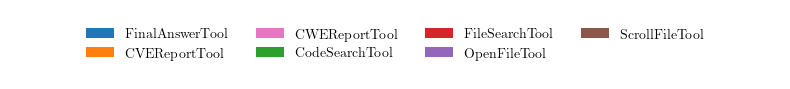

In [81]:
# Get handles and labels from any of your axes
handles, labels = ax.get_legend_handles_labels()
sorted_pairs = sorted(zip(handles, labels), key=lambda x: TOOL_ORDER.index(x[1]))
handles, labels = zip(*sorted_pairs)

# Create a dummy figure to host only the legend
fig_legend = plt.figure(figsize=(8, 1))
ax = fig_legend.add_subplot(111)
ax.axis('off')  # no axes

# Place legend in the figure
fig_legend.legend(
    handles, labels,
    frameon=False,
    ncol=4,
    loc="center"
)

fig_legend.tight_layout()
fig_legend.savefig('../figures/tool_calls_legend.pdf', bbox_inches='tight')
fig_legend.savefig('../figures/tool_calls_legend.pgf', bbox_inches='tight')
plt.show(fig_legend)

# Failure Classificatiion

In [1]:
import os

from openai import OpenAI

client = OpenAI(
    api_key="",
    base_url="https://vllm1.andstor.dev/v1"
    )

In [5]:
import tarfile
import re
import pickle

def load_pickle_from_tar(filepath, cve_id, commit_id):
    """
    Load the pickle corresponding to CVE-XXXX-YYYY_<commit_id>.pkl
    Returns the unpickled object, or None if not found.
    """
    pattern = fr"{re.escape(cve_id)}_{commit_id}\.pkl$"

    with tarfile.open(filepath, "r") as tar:
        for member in tar.getmembers():
            if not member.name.endswith(".pkl"):
                continue

            # Does this member match the requested CVE + commit?
            if re.search(pattern, member.name) is None:
                continue

            # Extract and load pickle
            f = tar.extractfile(member)
            if f is None:
                return None

            try:
                return pickle.load(f)
            except Exception as e:
                print(f"Error loading {member.name}: {e}")
                return None

    return None  # not found

In [6]:
from datasets import load_dataset

# Login using e.g. `huggingface-cli login` to access this dataset
ds = load_dataset("fals3/cvevc_cve")
df = ds["test"].to_pandas().set_index("cve")

/Users/andrestorhaug/Code/Projects/agentic-security-patch-classification-replication-package/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


<function random_array at 0x11c4bfc40>
<function random at 0x11c4bff60>
<function rand at 0x11c4d40e0>


In [ ]:
import tarfile
import pandas as pd
import re
import json
from tqdm import tqdm
import pickle


file_path = DATA_DIR / "output" / "PatchFinder_top10_gemma-3-27b-it-new-clean.jsonl"
tar_path = DATA_DIR / "output" / "PatchFinder_top10_gemma-3-27b-it.tar"
save_path = DATA_DIR / "analysis" / "PatchFinder_top10_gemma-3-27b-it_analysis.jsonl"


task = """
# Classification Task

Below is the run history of an agent. You will only see the agent's thoughts, reasoning steps, and tool calls — NOT any tool outputs.

Your task: determine why the agent produced an incorrect classification.

You must choose exactly one failure category from the table below:

| Category                      | Description |
|------------------------------|-------------|
| Superficial Association      | The model inferred a match due to keywords, filenames, or conceptual similarity without real evidence. |
| Failed to Find Relevant Context | The agent was not able to find the relevant files. |
| CVE Misinterpretation        | The model misinterpreted the CVE's root cause, vulnerable component, or exploit mechanism—resulting in a justification that does not align with the actual CVE description. |
| Memorized CVE                | The model did not retrieve the CVE report and concluded based on memory. |
| Incorrect Classification     | The agent collected reasonable evidence but came to the wrong conclusion. |
| Ran Out Of Budget            | The agent seemed to be on the right track, but the episode ended prematurely. |
| Gave Up Prematurely          | The agent decided to stop solving the problem after encountering some difficulty. |
| Other                        | There was some other problem that prevented the agent from correctly classifying the commit. |

CVE Description:

```
{cve_desc}
```

Guidance:
- You must infer whether the agent actually looked at file contents, performed searches, or accessed relevant code context.  
- If it reasoned only from filenames, commit message or keyword cues without accessing content, choose **Superficial Association**.  
- If it tried to retrieve context (search for code or open files) but never successfully used it, choose **Failed to Find Relevant Context**.  
- If its reasoning clearly contradicts or misunderstands the CVE description, choose **CVE Misinterpretation**.  
- If it never attempted to retrieve the CVE report, choose **Memorized CVE**.  
- If it reasoned properly and collected evidence but reached the wrong conclusion anyway, choose **Incorrect Classification**.  
- If the trace shows it hitting limits, timing out, or stopping mid-process, choose **Ran Out Of Budget** or **Gave Up Prematurely** depending on behavior.

Respond with the category in plain text, e.g., "Incorrect Classification".

Now analyze the agent's run history trace below:

```
{trace}
```

"""

with open(file_path, 'r') as f:
    with open(save_path, 'w') as out_f:
        for line in tqdm(f, total=12000):
            data = json.loads(line)
            if asbool(data["input"]["label"]) == asbool(data["output"]["answer"]):
                continue
            
            cve_id = data["input"]["cve"]
            commit_id = data["input"]["commit_id"]
            
            pickle_data = load_pickle_from_tar(tar_path, cve_id, commit_id)
            if pickle_data is None:
                print(f"Could not find pickle for {cve_id} {commit_id}")
                continue
            
            cve_desc = df.loc[cve_id]["desc"]
            history = ""
            for message in pickle_data.messages:
                if "task" in message and message["task"]:
                    history += message["task"] + "\n"
                if "model_output" in message and message["model_output"]:
                    history += "---" + "\n"
                    history += message["model_output"] + "\n"
                if "error" in message and message["error"]:
                    history += message["error"]["type"] + ": " + message["error"]["message"] + "\n"

            prompt = task.format(cve_desc=cve_desc, trace=history)
            
            try:
                response = client.chat.completions.create(
                    model="openai/gpt-oss-120b",
                    messages=[
                        {"role": "system", "content": "You are an expert analyst."},
                        {"role": "user", "content": prompt},
                    ],
                    reasoning_effort="high"
                )
                
                data["analysis"] = response.choices[0].message.content.strip()
                data["analysis_reasoning"] = response.choices[0].message.reasoning_content.strip()
                #print(prompt)
                #print(data["analysis_reasoning"])
                #print(data["analysis"])
                out_f.write(json.dumps(data) + "\n")
            except Exception as e:
                print("Error processing CVE:", data["input"]["cve"], e)

  1%|          | 131/12000 [14:18<40:21:37, 12.24s/it]

Error processing CVE: CVE-2010-3978 Error code: 400 - {'object': 'error', 'message': 'Expected 2 output messages (reasoning and final), but got 10.', 'type': 'BadRequestError', 'param': None, 'code': 400}


  1%|          | 135/12000 [17:12<79:15:44, 24.05s/it]

Error processing CVE: CVE-2010-3978 Error code: 400 - {'object': 'error', 'message': 'Expected 2 output messages (reasoning and final), but got 19.', 'type': 'BadRequestError', 'param': None, 'code': 400}


  1%|          | 137/12000 [19:24<117:34:48, 35.68s/it]

Error processing CVE: CVE-2010-3978 Error code: 400 - {'object': 'error', 'message': 'Expected 2 output messages (reasoning and final), but got 31.', 'type': 'BadRequestError', 'param': None, 'code': 400}


... (215 outputs left out)

Error processing CVE: CVE-2022-24774 Error code: 400 - {'object': 'error', 'message': 'Expected 2 output messages (reasoning and final), but got 6.', 'type': 'BadRequestError', 'param': None, 'code': 400}


12107it [18:16:42,  1.96s/it]                           

Error processing CVE: CVE-2022-31022 Error code: 400 - {'object': 'error', 'message': 'Expected 2 output messages (reasoning and final), but got 3.', 'type': 'BadRequestError', 'param': None, 'code': 400}


12222it [18:22:53,  5.41s/it]


In [7]:


analysis_dir = DATA_DIR / "analysis"
#"PatchFinder_top10_gemma-3-27b-it_analysis.jsonl"



In [ ]:

jsonl_files = [
 'PatchFinder_top10_Qwen3-235B-A22B-Instruct-2507.jsonl',
 'PatchFinder_top10_Llama-3.3-70B-Instruct.jsonl',
 'PatchFinder_top10_gemma-3-27b-it-new-clean.jsonl'
]

data = {}
for file in jsonl_files:

    subset = "_".join(file.split("_")[0:2])
    model = file.split("_")[-1].replace(".jsonl", "")
    print(subset, model)
    results_path = DATA_DIR / "output" / f"{subset}_{model}.jsonl"
    trace_path = DATA_DIR / "traces" / f"{subset}_{model}_traces.jsonl.zip"
    

PatchFinder_top10 Qwen3-235B-A22B-Instruct-2507
PatchFinder_top10 Llama-3.3-70B-Instruct
PatchFinder_top10 gemma-3-27b-it-new-clean


In [2]:
failure_categories = [
    "Superficial Association",
    "Failed to Find Relevant Context",
    "CVE Misinterpretation",
    "Memorized CVE",
    "Incorrect Classification",
    "Ran Out Of Budget",
    "Gave Up Prematurely",
    "Other"
]

failure_categories

['Superficial Association',
 'Failed to Find Relevant Context',
 'CVE Misinterpretation',
 'Memorized CVE',
 'Incorrect Classification',
 'Ran Out Of Budget',
 'Gave Up Prematurely',
 'Other']

In [9]:
df["analysis"]

KeyError: 'analysis'

In [293]:
df["analysis"].apply(lambda x: x if x in failure_categories else None).value_counts()

analysis
Superficial Association            453
CVE Misinterpretation              180
Failed to Find Relevant Context     88
Gave Up Prematurely                 29
Incorrect Classification            27
Memorized CVE                       21
Other                                5
Name: count, dtype: int64

In [298]:
subset = "_".join(str(analysis_file).split("_")[0:2])
subset

'../data/analysis/random_10'

PatchFinder_top10 gemma-3-27b-it


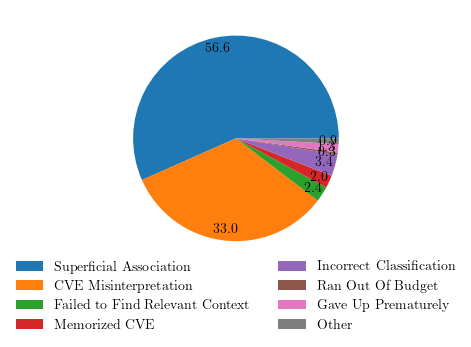

PatchFinder_top10 Qwen3-235B-A22B-Instruct-2507


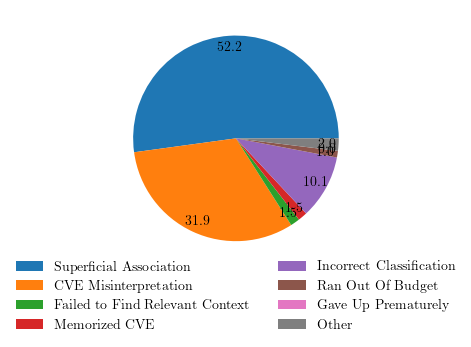

PatchFinder_top10 Llama-3.3-70B-Instruct


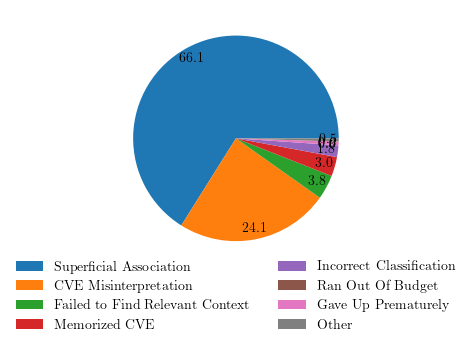

random_10 gemma-3-27b-it


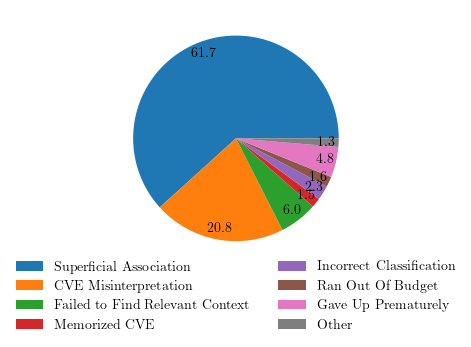

random_10 Qwen3-235B-A22B-Instruct-2507


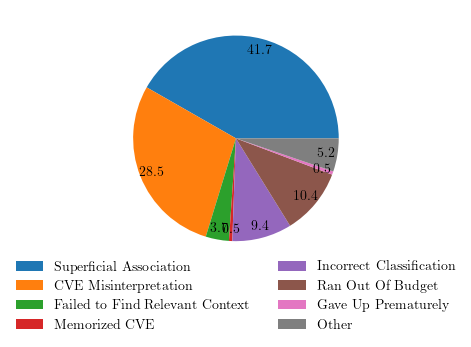

random_10 Llama-3.3-70B-Instruct


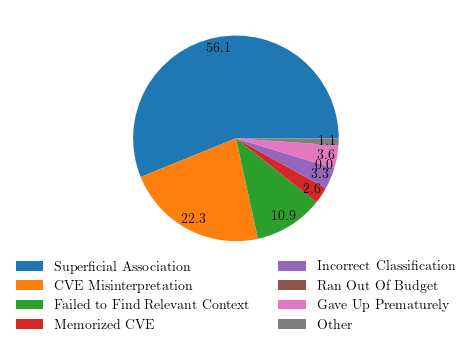

In [330]:
files = [
    "PatchFinder_top10_gemma-3-27b-it_analysis.jsonl",
    "PatchFinder_top10_Qwen3-235B-A22B-Instruct-2507_analysis.jsonl",
    "PatchFinder_top10_Llama-3.3-70B-Instruct_analysis.jsonl",

    "random_10_gemma-3-27b-it_analysis.jsonl",
    "random_10_Qwen3-235B-A22B-Instruct-2507_analysis.jsonl",
    "random_10_Llama-3.3-70B-Instruct_analysis.jsonl"
]

for file in files:
    subset = "_".join(str(file).split("_")[0:2])
    model = str(file).split("_")[-2].replace(".jsonl", "")
    print(subset, model)

    analysis_file = DATA_DIR / "analysis" / file

    df = pd.read_json(analysis_file, lines=True)

    # Count only known categories, others → "Other"
    vc = df["analysis"].apply(
        lambda x: x if x in CATEGORY_ORDER else "Other"
    ).value_counts()

    # Build full ordered vector with zeros for missing categories
    counts = pd.Series({cat: vc.get(cat, 0) for cat in CATEGORY_ORDER})

    fig, ax = plt.subplots(figsize=(4, 3.2))

    counts.plot.pie(
        labels=None,
        autopct=lambda p: f'{p:.1f}',
        pctdistance=0.89,
        ax=ax,
        colors=[COLOR_MAP[c] for c in counts.index],
    )

    ax.set_ylabel("")

    ax.legend(
        labels=counts.index,
        loc='lower center',
        bbox_to_anchor=(0.5, -0.3),
        ncol=2,
        frameon=False
    )

    fig.set_size_inches(w=3.3374, h=3.3374)

    fig.savefig(f'../figures/failure_analysis_{subset}_{model}.pdf', bbox_inches='tight')
    fig.savefig(f'../figures/failure_analysis_{subset}_{model}.pgf', bbox_inches='tight')

    plt.show()

In [309]:
counts.to_dict()

{'Superficial Association': 453,
 'CVE Misinterpretation': 180,
 'Failed to Find Relevant Context': 88,
 'Gave Up Prematurely': 29,
 'Incorrect Classification': 27,
 'Memorized CVE': 21,
 'Other': 5}

In [3]:
CATEGORY_ORDER = [
    "Superficial Association",
    "CVE Misinterpretation",
    "Failed to Find Relevant Context",
    "Memorized CVE",
    "Incorrect Classification",
    "Ran Out Of Budget",
    "Gave Up Prematurely",
    "Other"
]

COLOR_MAP = {
    "Superficial Association": "#1f77b4",   # blue
    "CVE Misinterpretation":   "#ff7f0e",   # orange
    "Failed to Find Relevant Context":  "#2ca02c",   # green
    "Memorized CVE":  "#d62728",   # red
    "Incorrect Classification":    "#9467bd",   # purple
    "Ran Out Of Budget":  "#8c564b",   # brown
    "Gave Up Prematurely":   "#e377c2",   # pink
    "Other": "#7f7f7f"  # gray
}


In [26]:
pd.read_json("../data/analysis/PatchFinder_top10_gemma-3-27b-it_analysis.jsonl", lines=True)

""


../data/analysis/PatchFinder_top10_gemma-3-27b-it_analysis.jsonl
../data/analysis/PatchFinder_top10_Qwen3-235B-A22B-Instruct-2507_analysis.jsonl
../data/analysis/PatchFinder_top10_Llama-3.3-70B-Instruct_analysis.jsonl


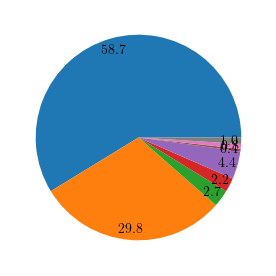

../data/analysis/random_10_gemma-3-27b-it_analysis.jsonl
../data/analysis/random_10_Qwen3-235B-A22B-Instruct-2507_analysis.jsonl
../data/analysis/random_10_Llama-3.3-70B-Instruct_analysis.jsonl


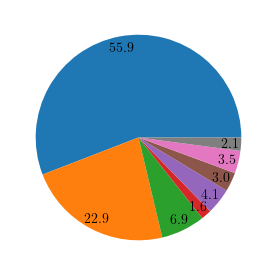

In [106]:
import pandas as pd
import matplotlib.pyplot as plt


files = [
    "gemma-3-27b-it_analysis.jsonl",
    "Qwen3-235B-A22B-Instruct-2507_analysis.jsonl",
    "Llama-3.3-70B-Instruct_analysis.jsonl"
]

ax = None

for subset in ["PatchFinder_top10", "random_10"]:
    # Count categories
    counts = {cat: 0 for cat in CATEGORY_ORDER}

    for file in files:
        analysis_file = DATA_DIR / "analysis" / (subset + "_" + file)
        df = pd.read_json(analysis_file, lines=True)
        print(analysis_file)
        vc = df["analysis"].apply(lambda x: x if x in CATEGORY_ORDER else "Other").value_counts()
        for cat, val in vc.items():
            counts[cat] += val

    # Convert to Series in correct category order
    counts = pd.Series(counts).loc[CATEGORY_ORDER]

    # Plot
    fig, ax = plt.subplots(figsize=(4, 3.2))
    counts.plot.pie(
        labels=None,
        colors=[COLOR_MAP[c] for c in counts.index],  # enforce colors
        autopct=lambda p: f'{p:.1f}',
        pctdistance=0.89,
        ax=ax
    )

    ax.set_ylabel("")

    # Legend in correct order + colors
   #ax.legend(
   #    handles=[
   #        plt.matplotlib.patches.Patch(color=COLOR_MAP[c], label=c)
   #        for c in CATEGORY_ORDER
   #    ],
   #    loc='lower center',
   #    bbox_to_anchor=(0.5, -0.3),
   #    ncol=2,
   #    frameon=False
   #)

    fig.set_size_inches(w=3.3374, h=3.3374)
    fig.savefig(f'../figures/failure_analysis_{subset}.pdf', bbox_inches='tight')
    fig.savefig(f'../figures/failure_analysis_{subset}.pgf', bbox_inches='tight')
    plt.show()

In [99]:
def keep_by_outcome(row, mode="match"):
    """
    Filter rows based on prediction outcome.

    mode:
        - "match"           -> keep correct predictions
        - "false_positive"  -> label=False, answer=True
        - "false_negative"  -> label=True, answer=False
        - "true_positive"   -> label=True, answer=True
        - "true_negative"   -> label=False, answer=False
    """
    try:
        input_label = row.get("input", {}).get("label", None)
        output_answer = row.get("output", {}).get("answer", None)

        if input_label is None or output_answer is None:
            return False

        label = asbool(input_label)
        pred = asbool(output_answer)

        if mode == "match":
            return label == pred
        elif mode == "false_positive":
            return (label is False) and (pred is True)
        elif mode == "false_negative":
            return (label is True) and (pred is False)
        elif mode == "true_positive":
            return (label is True) and (pred is True)
        elif mode == "true_negative":
            return (label is False) and (pred is False)
        else:
            raise ValueError(f"Unknown mode: {mode}")

    except Exception:
        return False


df = df[df.apply(keep_by_outcome, axis=1, mode="false_negative")]
df

""


In [97]:
counts

{'Superficial Association': 0,
 'CVE Misinterpretation': 0,
 'Failed to Find Relevant Context': 0,
 'Memorized CVE': 0,
 'Incorrect Classification': 0,
 'Ran Out Of Budget': 0,
 'Gave Up Prematurely': 0,
 'Other': 0}

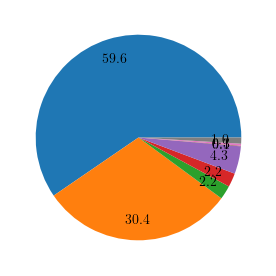

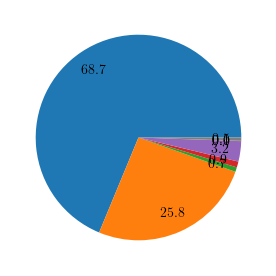

In [104]:
import pandas as pd
import matplotlib.pyplot as plt


mode="false_positive"

files = [
    "Qwen3-235B-A22B-Instruct-2507_analysis.jsonl",
    "gemma-3-27b-it_analysis.jsonl",
    "Llama-3.3-70B-Instruct_analysis.jsonl"
]

ax = None

for subset in ["PatchFinder_top10", "random_10"]:
    # Count categories
    counts = {cat: 0 for cat in CATEGORY_ORDER}

    for file in files:
        analysis_file = DATA_DIR / "analysis" / (subset + "_" + file)
        df = pd.read_json(analysis_file, lines=True)
        df = df[df.apply(keep_by_outcome, axis=1, mode=mode)]
        if df.empty:
            continue
        vc = df["analysis"].apply(lambda x: x if x in CATEGORY_ORDER else "Other").value_counts()
        for cat, val in vc.items():
            counts[cat] += val

    # Convert to Series in correct category order
    counts = pd.Series(counts).loc[CATEGORY_ORDER]

    if  counts.sum() == 0:
        continue

    # Plot
    fig, ax = plt.subplots(figsize=(4, 3.2))
    counts.plot.pie(
        labels=None,
        colors=[COLOR_MAP[c] for c in counts.index],  # enforce colors
        autopct=lambda p: f'{p:.1f}',
        pctdistance=0.80,
        ax=ax
    )

    ax.set_ylabel("")

    # Legend in correct order + colors
   #ax.legend(
   #    handles=[
   #        plt.matplotlib.patches.Patch(color=COLOR_MAP[c], label=c)
   #        for c in CATEGORY_ORDER
   #    ],
   #    loc='lower center',
   #    bbox_to_anchor=(0.5, -0.3),
   #    ncol=2,
   #    frameon=False
   #)

    fig.set_size_inches(w=3.3374, h=3.3374)
    fig.savefig(f'../figures/failure_analysis_{subset}_{mode}.pdf', bbox_inches='tight')
    fig.savefig(f'../figures/failure_analysis_{subset}_{mode}.pgf', bbox_inches='tight')
    plt.show()

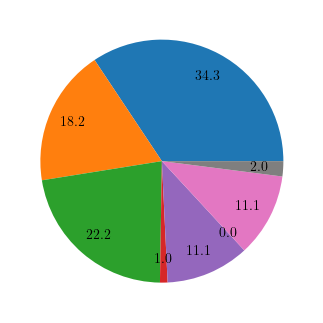

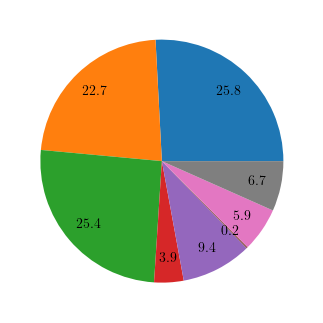

In [146]:
import pandas as pd
import matplotlib.pyplot as plt


mode="false_negative"

files = [
    "Qwen3-235B-A22B-Instruct-2507_analysis.jsonl",
    "gemma-3-27b-it_analysis.jsonl",
    "Llama-3.3-70B-Instruct_analysis.jsonl"
]

ax = None

for subset in ["PatchFinder_top10", "random_10"]:
    # Count categories
    counts = {cat: 0 for cat in CATEGORY_ORDER}

    for file in files:
        analysis_file = DATA_DIR / "analysis" / (subset + "_" + file)
        df = pd.read_json(analysis_file, lines=True)
        df = df[df.apply(keep_by_outcome, axis=1, mode=mode)]
        if df.empty:
            continue
        vc = df["analysis"].apply(lambda x: x if x in CATEGORY_ORDER else "Other").value_counts()
        for cat, val in vc.items():
            counts[cat] += val

    # Convert to Series in correct category order
    counts = pd.Series(counts).loc[CATEGORY_ORDER]

    if  counts.sum() == 0:
        continue

    # Plot
    fig, ax = plt.subplots(figsize=(4, 3.2))
    counts.plot.pie(
        labels=None,
        colors=[COLOR_MAP[c] for c in counts.index],  # enforce colors
        autopct=lambda p: f'{p:.1f}',
        pctdistance=0.80,
        ax=ax
    )

    ax.set_ylabel("")

    # Legend in correct order + colors
   #ax.legend(
   #    handles=[
   #        plt.matplotlib.patches.Patch(color=COLOR_MAP[c], label=c)
   #        for c in CATEGORY_ORDER
   #    ],
   #    loc='lower center',
   #    bbox_to_anchor=(0.5, -0.3),
   #    ncol=2,
   #    frameon=False
   #)

    fig.set_size_inches(w=3.3374, h=3.3374)
    fig.savefig(f'../figures/failure_analysis_{subset}_{mode}.pdf', bbox_inches='tight')
    fig.savefig(f'../figures/failure_analysis_{subset}_{mode}.pgf', bbox_inches='tight')
    plt.show()

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt


mode="false_negative"

files = [
    "Qwen3-235B-A22B-Instruct-2507_analysis.jsonl",
    "gemma-3-27b-it_analysis.jsonl",
    "Llama-3.3-70B-Instruct_analysis.jsonl"
]

ax = None

dfs = []
for subset in ["PatchFinder_top10", "random_10"]:
    for mode in ["false_negative", "false_positive"]:
    # Count categories
        counts = {cat: 0 for cat in CATEGORY_ORDER}

        for file in files:
            analysis_file = DATA_DIR / "analysis" / (subset + "_" + file)
            df = pd.read_json(analysis_file, lines=True)
            df = df[df.apply(keep_by_outcome, axis=1, mode=mode)]
            if df.empty:
                continue
            vc = df["analysis"].apply(lambda x: x if x in CATEGORY_ORDER else "Other").value_counts()
            for cat, val in vc.items():
                counts[cat] += val

        # Convert to Series in correct category order
        counts = pd.Series(counts).loc[CATEGORY_ORDER]

        if  counts.sum() == 0:
            continue
        
        df = pd.DataFrame(counts.copy())
        df["mode"] = mode
        df["subset"] = subset
        dfs.append(df)


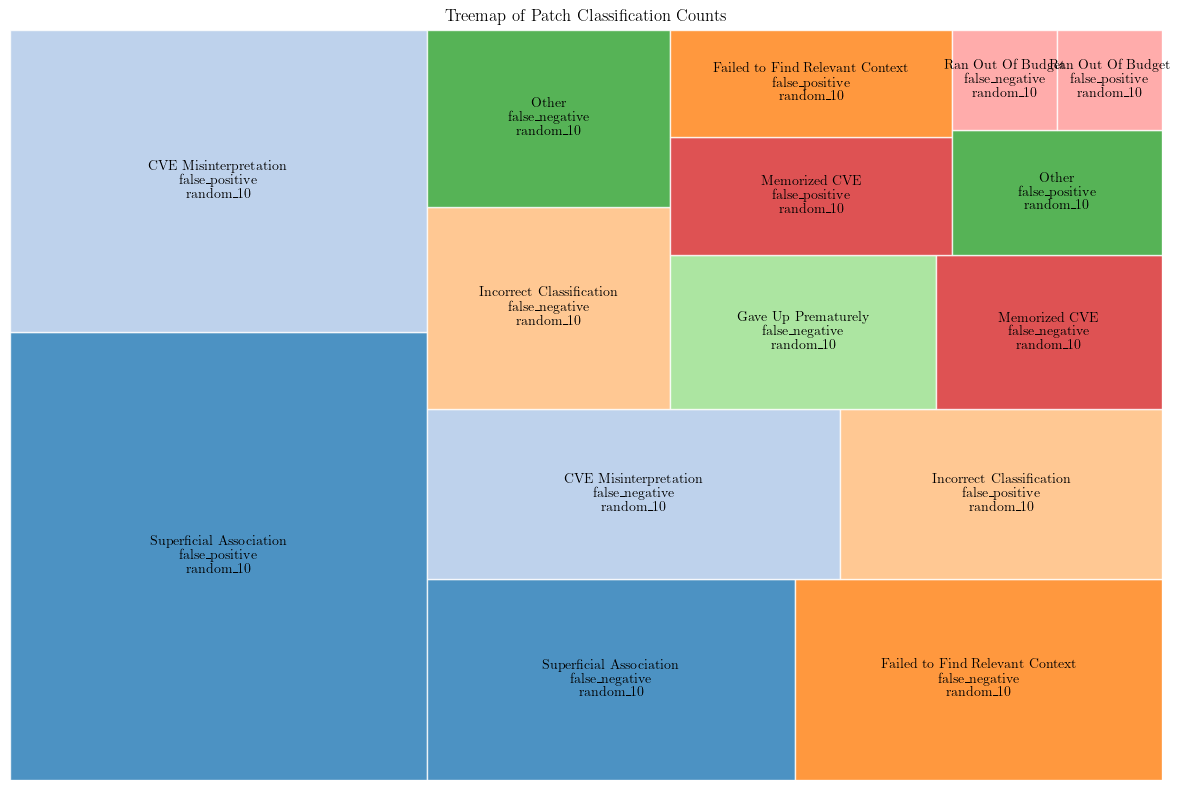

In [280]:
import pandas as pd
import matplotlib.pyplot as plt
import squarify  # pip install squarify

# Combine all dfs
if not dfs:
    raise ValueError("No data to plot!")

treemap_df = pd.concat(dfs).reset_index().rename(columns={"index": "category", 0: "count"})
treemap_df = treemap_df[treemap_df["subset"]=="random_10"]
treemap_df = treemap_df.sort_values("count", ascending=False)

# Optional: filter out zero-counts
treemap_df = treemap_df[treemap_df["count"] > 0]

# Exponential / power scaling
power = 0.4  # <1 compresses large, boosts small
treemap_df["scaled_count"] = treemap_df["count"]**power

# Choose colors per category (or mode)
colors = plt.cm.tab20.colors  # up to 20 distinct colors
color_map = {cat: colors[i % len(colors)] for i, cat in enumerate(treemap_df["category"].unique())}
treemap_df["color"] = treemap_df["category"].map(color_map)

# Plot
plt.figure(figsize=(12, 8))
squarify.plot(
    sizes=treemap_df["scaled_count"],
    label=treemap_df["category"] + "\n" + treemap_df["mode"] + "\n" + treemap_df["subset"],
    color=treemap_df["color"],
    alpha=0.8,
    pad=False,          # adds small padding between tiles
    bar_kwargs={"linewidth":1, "edgecolor":"white"}  # optional: white borders
)
plt.axis("off")
plt.title("Treemap of Patch Classification Counts")
plt.show()

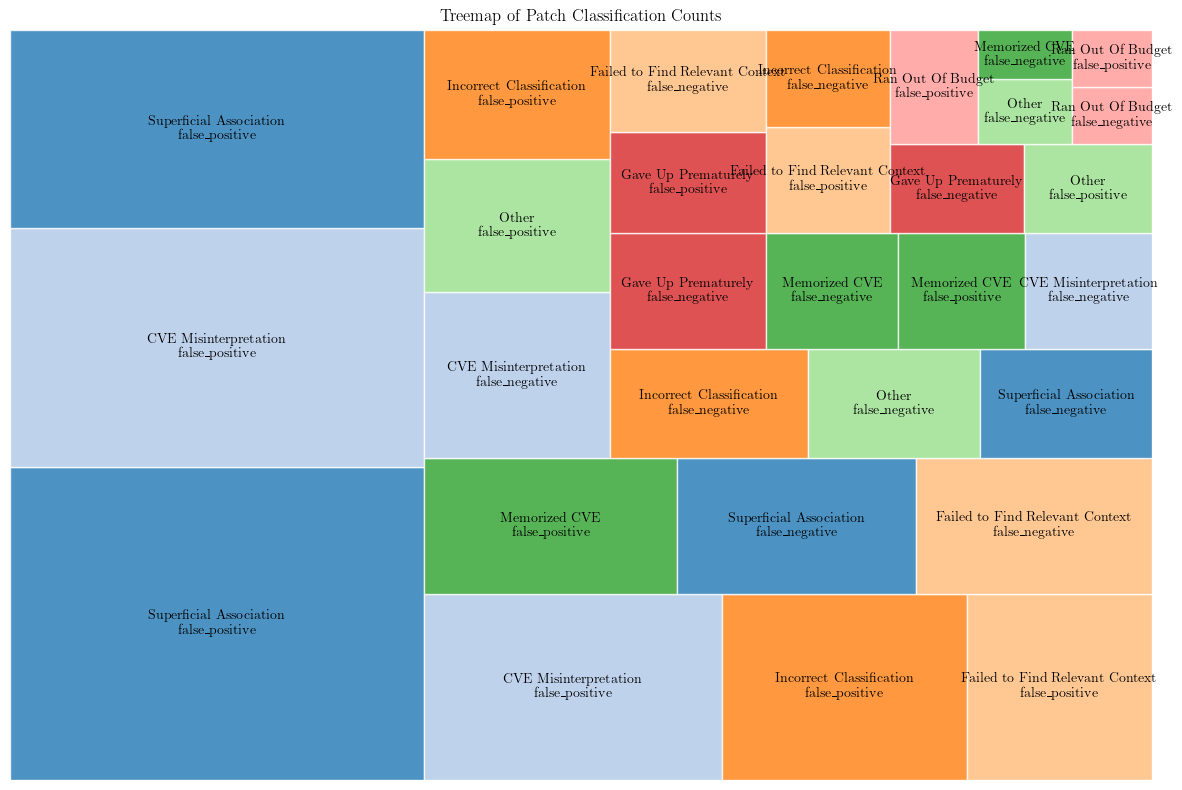

In [291]:
import pandas as pd
import matplotlib.pyplot as plt
import squarify  # pip install squarify

# Combine all dfs
if not dfs:
    raise ValueError("No data to plot!")

treemap_df = pd.concat(dfs).reset_index().rename(columns={"index": "category", 0: "count"})
#treemap_df = treemap_df[treemap_df["subset"]=="PatchFinder_top10"]
#treemap_df = treemap_df[treemap_df["mode"]=="false_negative"]
treemap_df = treemap_df.sort_values("count", ascending=False)

# Optional: filter out zero-counts
treemap_df = treemap_df[treemap_df["count"] > 0]

# Exponential / power scaling
power = 0.4  # <1 compresses large, boosts small
treemap_df["scaled_count"] = treemap_df["count"]**power

# Choose colors per category (or mode)
colors = plt.cm.tab20.colors  # up to 20 distinct colors
color_map = {cat: colors[i % len(colors)] for i, cat in enumerate(treemap_df["category"].unique())}
treemap_df["color"] = treemap_df["category"].map(color_map)

# Plot
plt.figure(figsize=(12, 8))
squarify.plot(
    sizes=treemap_df["scaled_count"],
    label=treemap_df["category"] + "\n" + treemap_df["mode"],
    color=treemap_df["color"],
    alpha=0.8,
    pad=False,          # adds small padding between tiles
    bar_kwargs={"linewidth":1, "edgecolor":"white"}  # optional: white borders
)
plt.axis("off")
plt.title("Treemap of Patch Classification Counts")
plt.show()

In [260]:
a = pd.concat(dfs)

#b = a[a["subset"]=="random_10"][0]#.to_dict()
a

,0,mode,subset
Superficial Association,34,false_negative,PatchFinder_top10
CVE Misinterpretation,18,false_negative,PatchFinder_top10
Failed to Find Relevant Context,22,false_negative,PatchFinder_top10
Memorized CVE,1,false_negative,PatchFinder_top10
Incorrect Classification,11,false_negative,PatchFinder_top10
Ran Out Of Budget,0,false_negative,PatchFinder_top10
Gave Up Prematurely,11,false_negative,PatchFinder_top10
Other,2,false_negative,PatchFinder_top10
Superficial Association,4209,false_positive,PatchFinder_top10
CVE Misinterpretation,2146,false_positive,PatchFinder_top10


(<Figure size 700x350 with 3 Axes>,
 {('false_negative', 'Superficial Association'): (0.0,
   np.float64(0.0),
   0.49751243781094534,
   np.float64(0.12214983713355047)),
  ('false_negative', 'CVE Misinterpretation'): (0.0,
   np.float64(0.12540716612377847),
   0.49751243781094534,
   np.float64(0.12214983713355047)),
  ('false_negative', 'Failed to Find Relevant Context'): (0.0,
   np.float64(0.25081433224755695),
   0.49751243781094534,
   np.float64(0.12214983713355047)),
  ('false_negative', 'Memorized CVE'): (0.0,
   np.float64(0.3762214983713355),
   0.49751243781094534,
   np.float64(0.12214983713355047)),
  ('false_negative', 'Incorrect Classification'): (0.0,
   np.float64(0.5016286644951139),
   0.49751243781094534,
   np.float64(0.12214983713355047)),
  ('false_negative', 'Ran Out Of Budget'): (0.0,
   np.float64(0.6270358306188925),
   0.49751243781094534,
   np.float64(0.12214983713355047)),
  ('false_negative', 'Gave Up Prematurely'): (0.0,
   np.float64(0.7524429967426

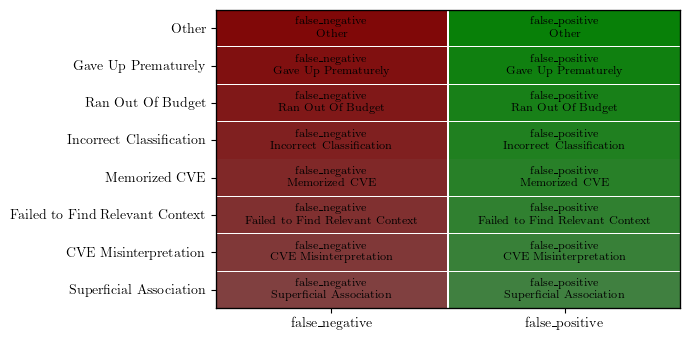

In [221]:
a = pd.concat(dfs).reset_index()
#a.set_index(["mode"], inplace=True)
mosaic(a[a["subset"]=="PatchFinder_top10"], ["mode","index"])

In [223]:
a

,index,0,mode,subset
0,Superficial Association,34,false_negative,PatchFinder_top10
1,CVE Misinterpretation,18,false_negative,PatchFinder_top10
2,Failed to Find Relevant Context,22,false_negative,PatchFinder_top10
3,Memorized CVE,1,false_negative,PatchFinder_top10
4,Incorrect Classification,11,false_negative,PatchFinder_top10
5,Ran Out Of Budget,0,false_negative,PatchFinder_top10
6,Gave Up Prematurely,11,false_negative,PatchFinder_top10
7,Other,2,false_negative,PatchFinder_top10
8,Superficial Association,4209,false_positive,PatchFinder_top10
9,CVE Misinterpretation,2146,false_positive,PatchFinder_top10
